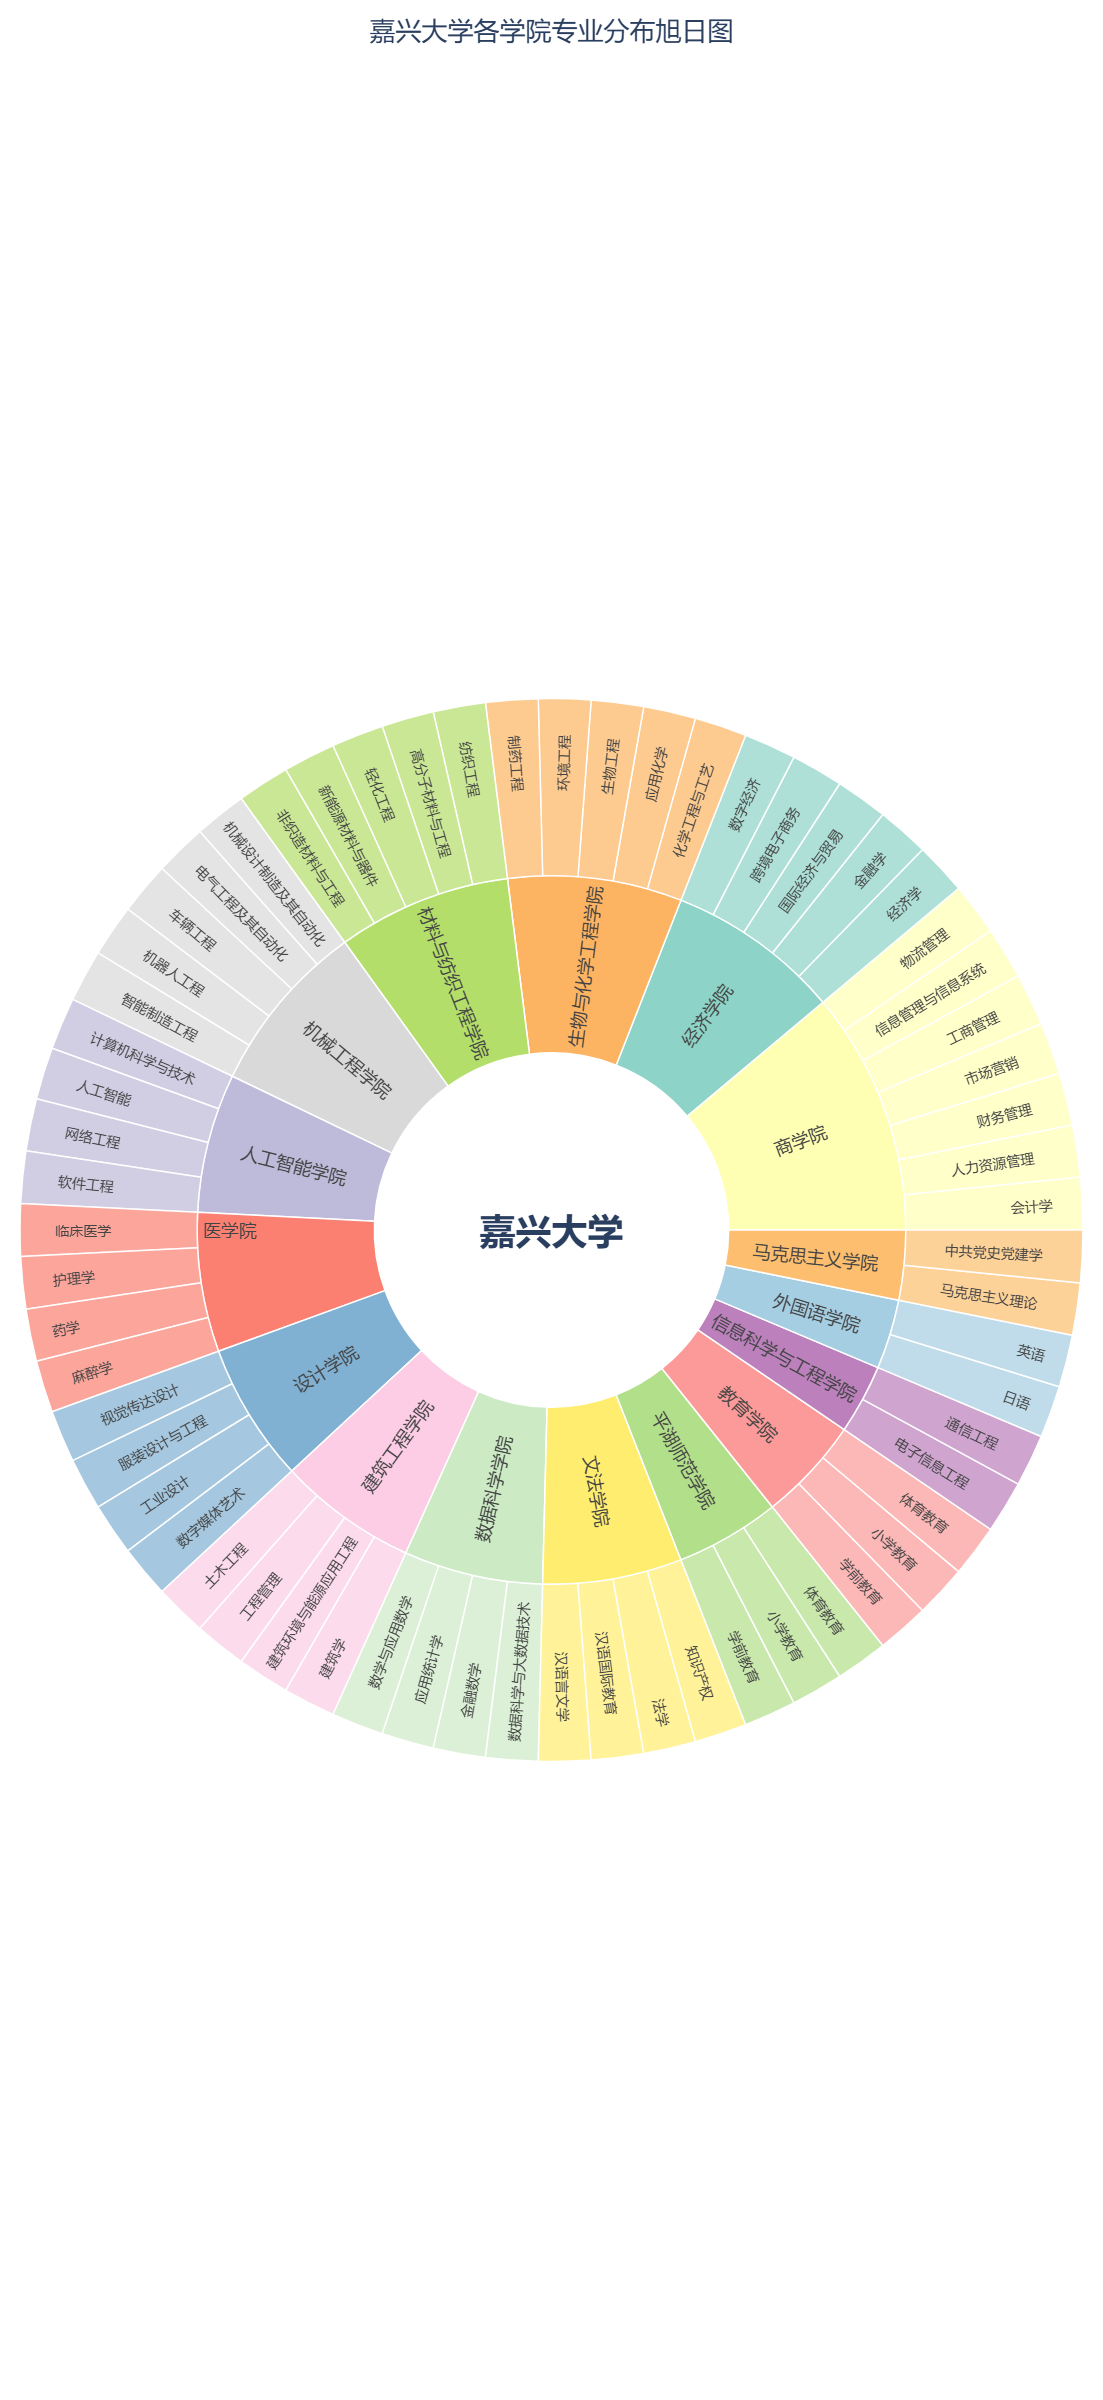

In [10]:
import plotly.graph_objects as go

colleges = {
    '经济学院': ['经济学', '金融学', '国际经济与贸易', '跨境电子商务', '数字经济'],
    '商学院': ['会计学', '人力资源管理', '财务管理', '市场营销', '工商管理',
               '信息管理与信息系统', '物流管理'],
    '人工智能学院': ['计算机科学与技术', '人工智能', '网络工程', '软件工程'],
    '医学院': ['临床医学', '护理学', '药学', '麻醉学'],
    '设计学院': ['视觉传达设计', '服装设计与工程', '工业设计', '数字媒体艺术'],
    '生物与化学工程学院': ['化学工程与工艺', '应用化学', '生物工程', '环境工程', '制药工程'],
    '材料与纺织工程学院': ['纺织工程', '高分子材料与工程', '轻化工程',
                           '新能源材料与器件', '非织造材料与工程'],
    '建筑工程学院': ['土木工程', '工程管理', '建筑环境与能源应用工程', '建筑学'],
    '机械工程学院': ['机械设计制造及其自动化', '电气工程及其自动化', '车辆工程',
                     '机器人工程', '智能制造工程'],
    '信息科学与工程学院': ['电子信息工程', '通信工程'],
    '数据科学学院': ['数学与应用数学', '应用统计学', '金融数学', '数据科学与大数据技术'],
    '文法学院': ['汉语言文学', '汉语国际教育', '法学', '知识产权'],
    '外国语学院': ['日语', '英语'],
    '平湖师范学院': ['学前教育', '小学教育', '体育教育'],
    '教育学院': ['学前教育', '小学教育', '体育教育'],
    '马克思主义学院': ['马克思主义理论', '中共党史党建学'],
}

root_id = "嘉兴大学"
root_label = "嘉兴大学"
total_majors = sum(len(m) for m in colleges.values())

ids      = [root_id]
labels   = [root_label]
parents  = [""]
values   = [total_majors]
colors   = ["#ffffff"]

# 关键：用 HTML 标签单独控制每一层的字体大小
texts    = ["<span style='font-size:36px'><b>嘉兴大学</b></span>"]

palette = [
    "#8dd3c7", "#ffffb3", "#bebada", "#fb8072", "#80b1d3",
    "#fdb462", "#b3de69", "#fccde5", "#d9d9d9", "#bc80bd",
    "#ccebc5", "#ffed6f", "#a6cee3", "#b2df8a", "#fb9a99",
    "#fdbf6f"
]

for i, (college, majors) in enumerate(colleges.items()):
    college_id = f"{root_id}/{college}"
    ids.append(college_id)
    labels.append(college)
    parents.append(root_id)
    values.append(len(majors))
    color = palette[i % len(palette)]
    colors.append(color)

    # 学院层字号：18px
    texts.append(f"<span style='font-size:18px'>{college}</span>")

    for major in majors:
        major_id = f"{college_id}/{major}"
        ids.append(major_id)
        labels.append(major)
        parents.append(college_id)
        values.append(1)
        colors.append(color)

        # 专业层字号：14px
        texts.append(f"<span style='font-size:14px'>{major}</span>")

fig = go.Figure(go.Sunburst(
    ids=ids,
    labels=labels,
    parents=parents,
    values=values,
    branchvalues="total",
    maxdepth=3,
    text=texts,                 # 使用自定义的带字号文本
    textinfo="text",            # 告诉 Plotly 显示我们提供的 text，而不是默认 label
    insidetextorientation="radial",
    marker=dict(colors=colors, line=dict(color="white", width=1.5)),
    textfont=dict(family="Microsoft YaHei, SimHei, sans-serif")  # 统一字体族
))

fig.update_layout(
    title=dict(
        text="嘉兴大学各学院专业分布旭日图",
        x=0.5,
        font=dict(size=26, family="Microsoft YaHei, SimHei, sans-serif")
    ),
    width=2400,
    height=2400,
    margin=dict(t=80, l=20, r=20, b=20)
)

fig.write_html("嘉兴大学专业分布旭日图.html",
               include_plotlyjs=True,   # 内嵌 JS，避免断网白屏
               full_html=True)
fig.show()